# DeFi Yield Aggregator with an ML Forensic Risk Engine — Proof-of-Process (pure Python)

This notebook implements the **implementation plan** end-to-end **without any on-chain component**. Everything that would be a Solidity contract, keeper network or fork simulator is replaced by a small, tested Python model, so the *process* (data → features → labels → models → gate → fork dry-run → vault → keeper → feedback loop) can be demonstrated and validated offline.

| Plan step | Where it lives here |
|---|---|
| 1 Feature store | §2 `build_features` (point-in-time, vectorised) |
| 2 Labeled dataset | §2 `match_incidents`, `label_rows` (forward window + post-incident quarantine) |
| 3 Train classifier + anomaly detector | §3 `ForensicEngine` |
| 4 Validate on held-out *time*, incident-level | §3 `evaluate_holdout` |
| 5 Gate = hard rules floor + model score + 3 tiers | §3 `hard_rule_flags`, `ForensicEngine.decide` |
| 6 Fork simulation dry-run | §4 `fork_dry_run` (stress scenarios on a vault copy) |
| 7 Vault contract | §4 `SimVault` (ERC-4626-style shares, roles, pause, slippage, reentrancy guard, atomic reverts) |
| 8 Keeper-triggered execution | §5 `Keeper`, `plan_moves` |
| 9 Testnet / audit | §7 unit + property tests, injected exploit scenarios |
| 10 Monitoring + retraining loop | §8 drift (PSI), decision log, human-feedback queue, `train_pipeline` re-run |

**Token/cost guard.** `USE_REAL_DATA = False` and `ALLOW_NETWORK = False` by default. The notebook runs on a **synthetic universe** with planted, noisy exploit precursors. Nothing touches the network unless you flip *both* flags yourself.

**Honest-reading note.** Synthetic results verify that the *machinery works* (no look-ahead, caps hold, vault invariants hold, gate blocks planted precursors). They are **not evidence of real-world exploit-prediction skill**. That requires running on real data (§9).

## 0 · Setup and configuration
All tunables live in one dataclass. Design rationale for the main ones:

* **Time-based split with purge** (train → purge → val → purge → test): labels look 7 days *forward*, so rows within 7 days before a cut-off would leak future information (López de Prado, *Advances in Financial ML*, ch. 7 "purging").
* **Validation set is separate from test**: thresholds are calibrated on validation negatives; the test period is touched once.
* **Quarantine** after an incident: post-exploit rows (TVL crash, erratic APY) are *not* "normal"; labelling them 0 would teach the anomaly model that wreckage is normal.

In [1]:
from __future__ import annotations
import copy, functools, json, re, sys, time, warnings
from collections import defaultdict
from dataclasses import dataclass
from difflib import get_close_matches
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.metrics import average_precision_score, roc_auc_score

try:
    from IPython.display import display
except ImportError:  # plain python
    display = print
warnings.filterwarnings("ignore", category=FutureWarning)


@dataclass
class Config:
    # ---- data source guards (both must be True to touch the network) ----
    USE_REAL_DATA: bool = False
    ALLOW_NETWORK: bool = False
    MAX_POOLS: int = 600
    MIN_TVL_FETCH: float = 1_000_000
    REQUEST_DELAY: float = 0.25
    ARTIFACT_DIR: str = "artifacts"
    SEED: int = 42
    # ---- synthetic universe ----
    N_PROJECTS: int = 40
    DAYS: int = 540
    N_INCIDENTS: int = 16
    # ---- labels / splits ----
    LOOKAHEAD_DAYS: int = 7
    COOLDOWN_DAYS: int = 30
    TRAIN_FRAC: float = 0.55
    VAL_FRAC: float = 0.20
    PURGE_DAYS: int = 7
    # ---- models ----
    MIN_POS_ROWS: int = 30
    MIN_POS_INCIDENTS: int = 5
    INCIDENT_WEIGHT_FRAC: float = 0.02   # each incident's total weight = 2% of negative mass
    BLOCK_FPR: float = 0.005             # val-negative false-positive budget for auto-block
    SIM_FPR: float = 0.02                # val-negative false-positive budget for mandatory fork-sim band
    # ---- hard-rule floor ----
    MAX_APY_PCT: float = 500.0
    MIN_TVL_USD: float = 500_000.0
    MAX_POOL_7D_DRAWDOWN: float = -0.30
    MAX_PROTO_7D_DRAWDOWN: float = -0.25
    # ---- allocation ----
    CAPITAL_USD: float = 1_000_000.0
    REWARD_HAIRCUT: float = 0.5          # reward-token APY counted at 50%
    APY_RANK_CAP: float = 50.0
    MIN_APY: float = 1.0
    RISK_AVERSION: float = 0.75
    POOL_CAP: float = 0.15
    PROTO_CAP: float = 0.25
    TVL_SHARE_CAP: float = 0.02          # never be >2% of a pool's TVL
    MAX_POSITIONS: int = 20
    # ---- execution / keeper ----
    MIN_TRADE_USD: float = 1_000.0
    REBALANCE_EVERY_DAYS: int = 7
    REBALANCE_HORIZON_DAYS: int = 30
    HURDLE_MULT: float = 2.0             # expected gain must exceed 2x costs
    DEX_DEPTH_USD: float = 100_000_000.0
    DEX_FEE_BPS: float = 30.0
    WITHDRAW_FEE_BPS: float = 5.0
    MAX_MOVE_LOSS_BPS: float = 150.0
    # ---- paper-world exploit model (assumption) ----
    EXPLOIT_LOSS_FRACTION: float = 0.8


CFG = Config()
ARTIFACTS = Path(CFG.ARTIFACT_DIR); ARTIFACTS.mkdir(exist_ok=True)
FEATURES = [
    "apy", "log_tvl", "tvl_ret_1", "tvl_ret_7", "tvl_ret_30", "tvl_dd_30",
    "apy_delta_7", "apy_vol_7", "apy_z_30", "apy_ratio_30", "reward_share",
    "apy_xs_pct", "proto_tvl_ret_7", "proto_tvl_dd_30",
]
print(f"USE_REAL_DATA={CFG.USE_REAL_DATA}  ALLOW_NETWORK={CFG.ALLOW_NETWORK}  -> synthetic universe will be used")

USE_REAL_DATA=False  ALLOW_NETWORK=False  -> synthetic universe will be used


## 1 · Data layer (synthetic by default)
`make_synthetic_universe` produces the **same schema** as the DeFiLlama pipeline: `pool, project, symbol, timestamp, tvlUsd, apy, apyBase, apyReward`, plus a hack feed in DeFiLlama's shape (`name, date[unix s], amount, chain`).

Planted realism so the pipeline is genuinely stressed:
* AR(1)/Ornstein-Uhlenbeck APY with project-level TVL factor (pools of one protocol co-move);
* **30% of incidents have no precursor at all** (unpredictable), the rest have a noisy 7-day ramp (APY spike plus either a TVL "hype pump" or a slow "bleed");
* **benign APY spikes** on non-exploited pools (false-positive traps);
* 2% missing rows, name variants in the hack feed (one needs a *reviewed alias*), and decoy events for protocols not in the universe.

`fetch_real_data` is the real DeFiLlama loader (resumable per-pool cache). It **raises unless both guard flags are True** and is never called in this run.

In [2]:
HEADERS = {"User-Agent": "defi-forensic-proof-of-process/2.0"}


def parse_dates(values: pd.Series) -> pd.Series:
    """Accept unix s, unix ms or ISO strings -> tz-aware UTC."""
    numeric = pd.to_numeric(values, errors="coerce")
    if numeric.notna().mean() > 0.8:
        unit = "ms" if numeric.dropna().abs().median() > 1e12 else "s"
        return pd.to_datetime(numeric, unit=unit, utc=True, errors="coerce")
    return pd.to_datetime(values, utc=True, errors="coerce")


def to_day_num(ts: pd.Series) -> np.ndarray:
    """tz-aware timestamps -> integer day number (days since epoch, UTC)."""
    return ts.dt.tz_convert("UTC").dt.tz_localize(None).values.astype("datetime64[D]").astype("int64")


def make_synthetic_universe(cfg: Config):
    rng = np.random.default_rng(cfg.SEED)
    T = cfg.DAYS
    days = pd.date_range("2025-01-01", periods=T, freq="D", tz="UTC")
    symbols = np.array(["USDC", "USDT", "DAI", "WETH", "WBTC", "stETH"])
    projects = [f"proto-{i:02d}" for i in range(cfg.N_PROJECTS)]
    assert cfg.N_INCIDENTS <= cfg.N_PROJECTS

    # ---- planted incidents (ground truth lives ONLY here; pipeline never reads it) ----
    ev_days = np.linspace(70, T - 12, cfg.N_INCIDENTS).astype(int) + rng.integers(-4, 5, cfg.N_INCIDENTS)
    ev_days = np.clip(ev_days, 40, T - 10)
    ev_projects = rng.choice(projects, size=cfg.N_INCIDENTS, replace=False)
    spec = {}
    for p, d in zip(ev_projects, ev_days):
        detectable = rng.random() < 0.7
        spec[p] = dict(day=int(d), strength=float(rng.uniform(0.6, 1.5)) if detectable else 0.0,
                       mode=str(rng.choice(["hype", "bleed"])), drop=float(rng.uniform(0.6, 0.95)))

    meta_rows, tvl_l, apy_l, rew_l = [], [], [], []
    t_idx = np.arange(T)
    for p in projects:
        n_pools = int(rng.integers(2, 6))
        proj_walk = np.cumsum(rng.normal(0, 0.02, T))
        proj_mult, apy_mult = np.ones(T), np.ones(T)
        s = spec.get(p)
        if s:
            d, w = s["day"], cfg.LOOKAHEAD_DAYS
            ramp = np.clip((t_idx - (d - w)) / w, 0, 1) * (t_idx < d)
            apy_mult = apy_mult * (1 + 2.5 * s["strength"] * ramp)
            proj_mult = proj_mult * ((1 + 0.15 * s["strength"] * ramp) if s["mode"] == "hype"
                                     else (1 - 0.20 * s["strength"] * ramp))
            post = t_idx >= d
            proj_mult = np.where(post, proj_mult * (1 - s["drop"]), proj_mult)
            apy_mult = np.where(post, 0.3, apy_mult)
        base_tvl = rng.lognormal(18.0, 1.0)
        reward_share = rng.uniform(0.0, 0.7)
        for k in range(n_pools):
            tvl = base_tvl * rng.uniform(0.15, 1.0) * np.exp(proj_walk + np.cumsum(rng.normal(0, 0.01, T))) * proj_mult
            mu = rng.lognormal(1.5, 0.6)
            noise = rng.normal(0, 0.15 * mu + 0.1, T)
            x = np.empty(T); x[0] = mu
            for t in range(1, T):
                x[t] = x[t - 1] + 0.08 * (mu - x[t - 1]) + noise[t]
            x = np.clip(x, 0.05, None)
            if (not s) and rng.random() < 0.3:          # benign spike (false-positive trap)
                b = int(rng.integers(40, T - 5)); x[b:b + 3] *= 3.0
            x = x * apy_mult
            meta_rows.append(dict(pool=f"{p}-pool{k}", project=p, symbol=str(rng.choice(symbols))))
            tvl_l.append(tvl); apy_l.append(x); rew_l.append(x * reward_share)

    meta = pd.DataFrame(meta_rows)
    n = len(meta)
    tvl, apy, rew = np.vstack(tvl_l), np.vstack(apy_l), np.vstack(rew_l)
    ts = pd.to_datetime(np.tile(days.tz_convert(None).values, n), utc=True)
    hist = pd.DataFrame({
        "pool": np.repeat(meta.pool.values, T), "project": np.repeat(meta.project.values, T),
        "symbol": np.repeat(meta.symbol.values, T), "timestamp": ts,
        "tvlUsd": tvl.ravel(), "apy": apy.ravel(), "apyReward": rew.ravel(),
    })
    hist["apyBase"] = hist["apy"] - hist["apyReward"]
    hist = hist.loc[rng.random(len(hist)) > 0.02].reset_index(drop=True)

    # ---- hack feed in DeFiLlama shape ----
    hacks, aliases = [], {}
    for i, (p, sp) in enumerate(spec.items()):
        name = p.replace("-", " ").title()                 # "Proto 03" -> normalises to proto03
        if i == 2:                                         # needs a reviewed alias
            name = f"{p} Finance"; aliases[name] = p
        hacks.append(dict(name=name, date=int(days[sp["day"]].timestamp()), amount=float(sp["drop"] * 1e7), chain="Ethereum"))
    for j in range(25):                                    # decoys
        hacks.append(dict(name=f"Unlisted Protocol {j}", date=int(days[int(rng.integers(0, T))].timestamp()), amount=1e6, chain="BSC"))
    hacks.append(dict(name="Proto 99", date=int(days[100].timestamp()), amount=5e5, chain="Ethereum"))
    return hist, hacks, aliases, meta, spec


def fetch_real_data(cfg: Config):
    """REAL DeFiLlama loader. NOT executed in this notebook run. Resumable per-pool cache."""
    if not (cfg.USE_REAL_DATA and cfg.ALLOW_NETWORK):
        raise RuntimeError("Network disabled. Set CFG.USE_REAL_DATA and CFG.ALLOW_NETWORK to True explicitly.")
    import requests
    from urllib.parse import quote
    raw = Path(cfg.ARTIFACT_DIR) / "raw"; (raw / "charts").mkdir(parents=True, exist_ok=True)

    def get(url, path):
        if path.exists():
            return json.loads(path.read_text(encoding="utf-8"))
        for attempt in range(3):
            try:
                r = requests.get(url, headers=HEADERS, timeout=30); r.raise_for_status(); data = r.json(); break
            except requests.RequestException:
                if attempt == 2: raise
                time.sleep(2 ** attempt)
        path.write_text(json.dumps(data), encoding="utf-8"); return data

    cat = get("https://yields.llama.fi/pools", raw / "pool_catalog.json")
    pools = pd.DataFrame(cat.get("data", cat) if isinstance(cat, dict) else cat)
    pools["tvlUsd"] = pd.to_numeric(pools["tvlUsd"], errors="coerce")
    sel = (pools.dropna(subset=["pool", "project", "tvlUsd"]).loc[lambda f: f.tvlUsd >= cfg.MIN_TVL_FETCH]
           .sort_values("tvlUsd", ascending=False).drop_duplicates("pool").head(cfg.MAX_POOLS))
    rows = []
    for r in sel.itertuples(index=False):
        payload = get(f"https://yields.llama.fi/chart/{quote(str(r.pool), safe='')}", raw / "charts" / f"{r.pool}.json")
        obs = payload.get("data", payload) if isinstance(payload, dict) else payload
        rows += [dict(pool=str(r.pool), project=str(r.project), symbol=str(getattr(r, "symbol", "")), **o) for o in obs if isinstance(o, dict)]
        time.sleep(cfg.REQUEST_DELAY)
    hist = pd.DataFrame(rows)
    hacks = get("https://api.llama.fi/hacks", raw / "hacks.json")
    meta = sel[["pool", "project"]].assign(symbol=sel.get("symbol", "USDC")).astype(str).reset_index(drop=True)
    return hist, hacks, {}, meta, None


def load_universe(cfg: Config):
    return fetch_real_data(cfg) if cfg.USE_REAL_DATA else make_synthetic_universe(cfg)


hist, hacks, ALIASES, meta, _truth = load_universe(CFG)
print(f"history rows={len(hist):,}  pools={hist.pool.nunique()}  projects={hist.project.nunique()}  hack-feed events={len(hacks)}")
display(hist.head(3))

history rows=76,798  pools=145  projects=40  hack-feed events=42


,pool,project,symbol,timestamp,tvlUsd,apy,apyReward,apyBase
0,proto-00-pool0,proto-00,DAI,2025-01-01 00:00:00+00:00,4.711584e+07,1.914372,0.065614,1.848757
1,proto-00-pool0,proto-00,DAI,2025-01-02 00:00:00+00:00,4.705766e+07,1.773733,0.060794,1.712939
2,proto-00-pool0,proto-00,DAI,2025-01-03 00:00:00+00:00,4.766543e+07,1.686411,0.057801,1.628610


## 2 · Feature store and labels (plan steps 1–2)

**Features** are *point-in-time*: every value at day *t* uses only data ≤ *t* (verified by a look-ahead test in §7). Compared with the original notebook the set is richer and closer to the plan's list (TVL change, oracle/price-divergence stand-ins, utilisation stand-ins):

| Feature | Rationale |
|---|---|
| `tvl_ret_{1,7,30}`, `tvl_dd_30` | liquidity flight / drawdown from 30-day peak |
| `apy_z_30`, `apy_ratio_30` | APY vs its *own lagged* 30-day baseline (lag avoids self-dampening) |
| `apy_delta_7`, `apy_vol_7` | rate instability |
| `reward_share` | incentive-driven yield is fragile and often precedes rug/depeg |
| `apy_xs_pct` | cross-sectional rank among all pools that day (anomalous yield relative to market) |
| `proto_tvl_ret_7`, `proto_tvl_dd_30` | **protocol-level** TVL (sum over pools, forward-filled ≤3 days so missing rows don't fake a drop) |

**Labels**: positives = rows of the incident's protocol in `[event − 7d, event)`. Rows in `[event, event+30d)` are **quarantined** (excluded from training and evaluation). Only exact-normalised names or a *reviewed* alias auto-match; fuzzy candidates are emitted for human review, never auto-accepted.

In [3]:
def normalize_name(s) -> str:
    return re.sub(r"[^a-z0-9]", "", str(s).lower())


def build_features(history: pd.DataFrame, cfg: Config = CFG) -> pd.DataFrame:
    df = history.copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True).dt.floor("D")
    for c in ("tvlUsd", "apy", "apyBase", "apyReward"):
        df[c] = pd.to_numeric(df[c], errors="coerce") if c in df else np.nan
    df = df.dropna(subset=["tvlUsd", "apy"])
    df = df[(df.tvlUsd > 0) & (df.apy >= 0)]
    df["apyReward"] = df["apyReward"].fillna(0.0).clip(lower=0)
    df["apyBase"] = df["apyBase"].fillna(df["apy"] - df["apyReward"]).clip(lower=0)
    df["day_num"] = to_day_num(df["timestamp"])
    df = df.sort_values(["pool", "day_num"]).drop_duplicates(["pool", "day_num"], keep="last").reset_index(drop=True)
    df["apy_eff"] = df["apyBase"] + cfg.REWARD_HAIRCUT * df["apyReward"]

    df["log_tvl"] = np.log1p(df["tvlUsd"])
    df["_apy_lag"] = df.groupby("pool", sort=False)["apy"].shift(1)
    g = df.groupby("pool", sort=False)

    def roll(col, w, fn, mp):
        return getattr(g[col].rolling(w, min_periods=mp), fn)().reset_index(level=0, drop=True)

    for k in (1, 7, 30):
        df[f"tvl_ret_{k}"] = g["tvlUsd"].pct_change(k, fill_method=None).clip(-1, 10)
    df["tvl_dd_30"] = df["tvlUsd"] / roll("tvlUsd", 30, "max", 5) - 1
    m30, s30 = roll("_apy_lag", 30, "mean", 10), roll("_apy_lag", 30, "std", 10)
    df["apy_z_30"] = ((df["apy"] - m30) / (s30 + 1e-6)).clip(-10, 10)
    df["apy_ratio_30"] = (df["apy"] / (m30 + 1e-6)).clip(0, 20)
    df["apy_delta_7"] = g["apy"].diff(7)
    df["apy_vol_7"] = roll("apy", 7, "std", 3)
    df["reward_share"] = (df["apyReward"] / (df["apy"] + 1e-6)).clip(0, 1)
    df["apy_xs_pct"] = df.groupby("day_num")["apy"].rank(pct=True)

    # protocol-level TVL (forward-fill <=3 days so missing rows do not create fake drops)
    wide = df.pivot(index="day_num", columns="pool", values="tvlUsd").sort_index()
    wide = wide.reindex(range(int(wide.index.min()), int(wide.index.max()) + 1)).ffill(limit=3)
    proj_of = df.drop_duplicates("pool").set_index("pool")["project"].reindex(wide.columns)
    proto = wide.T.groupby(proj_of.values).sum(min_count=1).T
    ret7 = proto.pct_change(7, fill_method=None).clip(-1, 10)
    dd30 = proto / proto.rolling(30, min_periods=5).max() - 1
    long = (ret7.reset_index().melt(id_vars="day_num", var_name="project", value_name="proto_tvl_ret_7")
            .merge(dd30.reset_index().melt(id_vars="day_num", var_name="project", value_name="proto_tvl_dd_30"),
                   on=["day_num", "project"]))
    df = df.merge(long, on=["day_num", "project"], how="left")
    df = df.drop(columns=["_apy_lag"]).replace([np.inf, -np.inf], np.nan).dropna(subset=FEATURES)
    return df.sort_values(["pool", "day_num"]).reset_index(drop=True)


def match_incidents(hack_feed, projects, day_range, aliases):
    ev = pd.DataFrame(hack_feed)
    name_col = next(c for c in ("name", "protocol", "project") if c in ev.columns)
    date_col = next(c for c in ("date", "timestamp", "time") if c in ev.columns)
    ev["event_name"] = ev[name_col].astype(str)
    ev["event_time"] = parse_dates(ev[date_col])
    ev = ev.dropna(subset=["event_time"]).reset_index(drop=True)
    ev["event_day"] = to_day_num(ev["event_time"])
    proj_norm = {normalize_name(p): p for p in projects}
    alias_norm = {normalize_name(k): v for k, v in aliases.items()}
    proj, method = [], []
    for n in ev.event_name:
        k = normalize_name(n)
        if k in alias_norm:   proj.append(alias_norm[k]); method.append("reviewed alias")
        elif k in proj_norm:  proj.append(proj_norm[k]);  method.append("normalized exact name")
        else:                 proj.append(None);          method.append("")
    ev["project"], ev["match_method"] = proj, method
    in_range = ev.event_day.between(*day_range)
    matched = ev[ev.project.notna() & in_range].drop_duplicates(["project", "event_day"]).copy()
    matched["event_id"] = matched.project + "|" + matched.event_day.astype(str)
    review = ev[ev.project.isna() & in_range].copy()
    keys = list(proj_norm)
    review["suggested_project"] = [
        (proj_norm[m[0]] if (m := get_close_matches(normalize_name(n), keys, n=1, cutoff=0.75)) else "")
        for n in review.event_name]
    cols = ["project", "event_name", "event_time", "event_day", "event_id", "match_method"]
    return matched[cols].reset_index(drop=True), review[review.suggested_project != ""][["event_name", "event_time", "suggested_project"]]


def label_rows(feat: pd.DataFrame, incidents: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    out = feat.copy()
    d, proj = out.day_num.values, out.project.values
    label = np.zeros(len(out), np.int8); inc = np.full(len(out), "", dtype=object); quar = np.zeros(len(out), bool)
    for r in incidents.itertuples(index=False):
        m = proj == r.project
        pos = m & (d >= r.event_day - cfg.LOOKAHEAD_DAYS) & (d < r.event_day)
        quar |= m & (d >= r.event_day) & (d < r.event_day + cfg.COOLDOWN_DAYS)
        label[pos] = 1; inc[pos] = r.event_id
    label[quar] = 0
    out["label"], out["incident_id"], out["quarantine"] = label, inc, quar
    return out


def make_splits(feat: pd.DataFrame, cfg: Config):
    days = np.sort(feat.day_num.unique())
    t1 = int(days[int(len(days) * cfg.TRAIN_FRAC)]); t2 = int(days[int(len(days) * (cfg.TRAIN_FRAC + cfg.VAL_FRAC))])
    d, P = feat.day_num.values, cfg.PURGE_DAYS
    split = np.full(len(feat), "purge", dtype=object)
    split[d < t1 - P] = "train"; split[(d >= t1) & (d < t2 - P)] = "val"; split[d >= t2] = "test"
    return split, t1, t2


feat = build_features(hist)
incidents, review_queue = match_incidents(hacks, feat.project.unique(), (int(feat.day_num.min()), int(feat.day_num.max())), ALIASES)
feat = label_rows(feat, incidents, CFG)
feat["split"], T1, T2 = make_splits(feat, CFG)
incidents["split"] = np.where(incidents.event_day < T1, "train", np.where(incidents.event_day < T2, "val", "test"))

print(f"feature rows={len(feat):,}  positives={int(feat.label.sum())}  quarantined={int(feat.quarantine.sum())}")
print("matched incidents by split:", incidents.split.value_counts().to_dict(), "| match methods:", incidents.match_method.value_counts().to_dict())
print("unmatched events with a fuzzy suggestion (HUMAN REVIEW REQUIRED, not auto-accepted):")
display(review_queue.head())
if _truth is not None:   # synthetic-only sanity: plumbing recovered every planted incident
    assert len(incidents) == CFG.N_INCIDENTS, "label plumbing failed to recover planted incidents"

feature rows=72,448  positives=457  quarantined=1878
matched incidents by split: {'train': 8, 'val': 4, 'test': 4} | match methods: {'normalized exact name': 15, 'reviewed alias': 1}
unmatched events with a fuzzy suggestion (HUMAN REVIEW REQUIRED, not auto-accepted):


,event_name,event_time,suggested_project
41,Proto 99,2025-04-11 00:00:00+00:00,proto-39


## 3 · Forensic risk engine (plan steps 3–5)

**Two complementary models** (plan §3):
* **Isolation Forest** (Liu, Ting & Zhou 2008) fitted on *normal* training rows only: catches novel patterns without labels.
* **Gradient-boosted trees** (`HistGradientBoostingClassifier`, shallow, L2-regularised) on labelled precursors. Rows of one incident are strongly correlated, so I use **incident-balanced weights**: each incident gets the same total weight (`INCIDENT_WEIGHT_FRAC` × negative mass) no matter how many pool-days it spans. The classifier trains only if ≥ `MIN_POS_INCIDENTS` independent incidents are available.

**Score normalisation.** Raw scores from the two models are not comparable, so each is mapped to a **mid-rank percentile against the validation negatives** (a held-out "what normal looks like" reference). The combined risk = `max(anomaly_pct, classifier_pct)` ("flag if either fires", as in the plan).

**Thresholds are set by a false-positive budget on validation**, not by a hand-picked 0.7: `BLOCK_FPR` → auto-block, `SIM_FPR` → mandatory fork-sim band. Test data never influences a threshold.

**Gate tiers**: `BLOCK_RULE` (hard-rule floor, always wins) → `BLOCK_MODEL` → `SIMULATE` → `ALLOW`.

In [4]:
def hard_rule_flags(df: pd.DataFrame, cfg: Config):
    """Transparent rule floor. Evaluated independently of any model score."""
    rules = {
        "apy_above_ceiling": df["apy"] >= cfg.MAX_APY_PCT,
        "tvl_below_minimum": df["tvlUsd"] < cfg.MIN_TVL_USD,
        "pool_tvl_drawdown": df["tvl_ret_7"] <= cfg.MAX_POOL_7D_DRAWDOWN,
        "protocol_tvl_drawdown": df["proto_tvl_ret_7"] <= cfg.MAX_PROTO_7D_DRAWDOWN,
        "incentive_only_farm": (df["reward_share"] > 0.95) & (df["apy"] > 100),
    }
    reasons = pd.Series("", index=df.index); flag = pd.Series(False, index=df.index)
    for name, m in rules.items():
        m = m.fillna(False)
        reasons = reasons.where(~m, reasons + name + ";"); flag |= m
    return flag, reasons


def _mid_rank_pct(ref_sorted: np.ndarray, x: np.ndarray) -> np.ndarray:
    return (np.searchsorted(ref_sorted, x, "left") + np.searchsorted(ref_sorted, x, "right")) / (2 * len(ref_sorted))


class ForensicEngine:
    def __init__(self, cfg: Config):
        self.cfg = cfg; self.clf = None; self.status = "not fitted"

    def _raw(self, X):
        a = -self.iforest.decision_function(X[FEATURES])
        c = self.clf.predict_proba(X[FEATURES])[:, 1] if self.clf is not None else None
        return a, c

    def fit(self, train: pd.DataFrame, val: pd.DataFrame):
        cfg = self.cfg
        tr = train[~train.quarantine]
        neg = tr[tr.label == 0]
        self.iforest = IsolationForest(n_estimators=300, max_samples=256, contamination="auto",
                                       random_state=cfg.SEED, n_jobs=-1).fit(neg[FEATURES])
        pos = tr[tr.label == 1]; n_inc = pos.incident_id.nunique()
        if len(pos) >= cfg.MIN_POS_ROWS and n_inc >= cfg.MIN_POS_INCIDENTS:
            per_inc = pos.incident_id.value_counts()
            w = np.ones(len(tr)); y = tr.label.values
            w[y == 1] = (len(neg) * cfg.INCIDENT_WEIGHT_FRAC) / per_inc.reindex(tr.loc[y == 1, "incident_id"]).values
            self.clf = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, l2_regularization=1.0,
                                                      min_samples_leaf=50, random_state=cfg.SEED)
            self.clf.fit(tr[FEATURES], y, sample_weight=w)
            self.status = f"trained (classifier on {len(pos)} rows / {n_inc} incidents + isolation forest)"
        else:
            self.status = f"anomaly-only (need >={cfg.MIN_POS_ROWS} rows and >={cfg.MIN_POS_INCIDENTS} incidents; have {len(pos)}/{n_inc})"
        vneg = val[(val.label == 0) & (~val.quarantine)]
        a, c = self._raw(vneg)
        self.ref_a = np.sort(a); self.ref_c = np.sort(c) if c is not None else None
        comb = self.score(vneg)["risk_score"].values
        self.t_block = float(np.quantile(comb, 1 - cfg.BLOCK_FPR))
        self.t_sim = float(min(np.quantile(comb, 1 - cfg.SIM_FPR), self.t_block))
        return self

    def score(self, df: pd.DataFrame) -> pd.DataFrame:
        a, c = self._raw(df)
        out = pd.DataFrame(index=df.index)
        out["anomaly_pct"] = _mid_rank_pct(self.ref_a, a)
        out["clf_pct"] = _mid_rank_pct(self.ref_c, c) if c is not None else np.nan
        out["risk_score"] = np.fmax(out.anomaly_pct, out.clf_pct.fillna(0.0))
        return out

    def decide(self, df: pd.DataFrame) -> pd.DataFrame:
        out = df.copy()
        sc = self.score(df)
        for col in sc: out[col] = sc[col].values
        hard, reasons = hard_rule_flags(out, self.cfg)
        out["hard_rule"], out["rule_reasons"] = hard.values, reasons.values
        out["verdict"] = np.select(
            [out.hard_rule, out.risk_score >= self.t_block, out.risk_score >= self.t_sim],
            ["BLOCK_RULE", "BLOCK_MODEL", "SIMULATE"], default="ALLOW")
        return out


def train_pipeline(feat_labeled: pd.DataFrame, cfg: Config) -> ForensicEngine:
    """Full (re)training entry point — the monthly retraining loop in §8 calls exactly this."""
    return ForensicEngine(cfg).fit(feat_labeled[feat_labeled.split == "train"], feat_labeled[feat_labeled.split == "val"])


engine = train_pipeline(feat, CFG)
scored = engine.decide(feat)
print("engine:", engine.status)
print(f"thresholds (from validation negatives): simulate>={engine.t_sim:.4f}  block>={engine.t_block:.4f}")

engine: trained (classifier on 221 rows / 8 incidents + isolation forest)
thresholds (from validation negatives): simulate>=0.9895  block>=0.9974


### Held-out evaluation (plan step 4)
Row-level PR-AUC is reported but **flagged as optimistic**: rows from one incident are correlated. The decision-relevant view is **incident-level**: *was the incident's protocol flagged at least once in the 7 days before it, and how early?* Each incident is compared with the detection probability of **random alerting at the same alert rate** (`1-(1-a)^n`), a trivial but honest baseline.

In [5]:
def evaluate_holdout(scored: pd.DataFrame, incidents: pd.DataFrame):
    te = scored[(scored.split == "test") & (~scored.quarantine)]
    res, y = {}, te.label.values
    res["test_rows"], res["test_positive_rows"] = len(te), int(y.sum())
    if 0 < y.sum() < len(y):
        res["pr_auc"] = average_precision_score(y, te.risk_score); res["base_rate"] = float(y.mean())
        res["roc_auc"] = roc_auc_score(y, te.risk_score)
    neg = te[te.label == 0]
    res["alert_rate_on_negatives"] = float(neg.verdict.ne("ALLOW").mean())
    res["block_rate_on_negatives"] = float(neg.verdict.isin(["BLOCK_RULE", "BLOCK_MODEL"]).mean())
    inc_day = incidents.set_index("event_id")["event_day"]; a = res["alert_rate_on_negatives"]; rows = []
    for iid, g in te[te.label == 1].groupby("incident_id"):
        fl = g[g.verdict != "ALLOW"]
        rows.append(dict(incident_id=iid, pre_window_rows=len(g), detected=len(fl) > 0,
                         lead_days=(inc_day[iid] - fl.day_num.min()) if len(fl) else np.nan,
                         by_rule=bool((fl.verdict == "BLOCK_RULE").any()),
                         by_model=bool(fl.verdict.isin(["BLOCK_MODEL", "SIMULATE"]).any()),
                         chance_detection=1 - (1 - a) ** len(g)))
    inc_tbl = pd.DataFrame(rows)
    if len(inc_tbl):
        res["incident_detection_rate"] = float(inc_tbl.detected.mean())
        res["chance_detection_rate"] = float(inc_tbl.chance_detection.mean())
        res["median_lead_days"] = float(inc_tbl.lead_days.median())
    return res, inc_tbl


holdout, incident_table = evaluate_holdout(scored, incidents)
print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in holdout.items()}, indent=2))
display(incident_table)
print("Reading guide: compare incident_detection_rate with chance_detection_rate; PR-AUC rows are correlated (optimistic).")

{
  "test_rows": 17659,
  "test_positive_rows": 135,
  "pr_auc": 0.1969,
  "base_rate": 0.0076,
  "roc_auc": 0.8268,
  "alert_rate_on_negatives": 0.0512,
  "block_rate_on_negatives": 0.0336,
  "incident_detection_rate": 1.0,
  "chance_detection_rate": 0.8301,
  "median_lead_days": 5.5
}


,incident_id,pre_window_rows,detected,lead_days,by_rule,by_model,chance_detection
0,proto-03|20619,34,True,6,False,True,0.832451
1,proto-12|20527,33,True,6,False,True,0.823412
2,proto-20|20557,35,True,5,False,True,0.841027
3,proto-25|20588,33,True,5,False,True,0.823412


Reading guide: compare incident_detection_rate with chance_detection_rate; PR-AUC rows are correlated (optimistic).


## 4 · Python stand-ins for the on-chain layer (plan steps 6–7)

### `SimVault` — the vault contract as a Python state machine
Mirrors the plan's contract design so the *logic* can be tested without Solidity:

* ERC-4626-style **shares** (`deposit`/`withdraw`), share price = assets / shares;
* **roles**: only the keeper may `rebalance` (`onlyKeeper`), only the guardian may `pause`/`unpause` (circuit breaker);
* **slippage protection**: `rebalance(..., min_out)` reverts if the output is below `min_out`;
* **reentrancy guard** + **atomic transactions**: any `Revert` rolls state back to the pre-call snapshot (what the EVM does), proven by tests in §7;
* **events** (`Deposit`, `RebalanceExecuted`, `Loss`…) are appended to a log consumed by the feedback loop.

### `fork_dry_run` — the Tenderly/Hardhat fork stand-in
Executes the *same* `rebalance` on a **copy** of the vault under stress scenarios (nominal, sandwich, thin liquidity, hostile destination fee) and checks the balance delta vs a loss budget plus a no-free-money invariant. The stress parameters are **assumptions**, not measurements.

In [6]:
KEEPER, GUARDIAN = "keeper", "guardian"


class Revert(Exception):
    """EVM-style revert."""


def tx(fn):
    """Atomic + non-reentrant transaction: snapshot, run, roll back on any exception."""
    @functools.wraps(fn)
    def wrapper(self, *a, **k):
        if self._lock:
            raise Revert("Reentrancy")
        snap = {key: copy.deepcopy(val) for key, val in self.__dict__.items() if key != "events"}
        n_events = len(self.events)
        self._lock = True
        try:
            return fn(self, *a, **k)
        except BaseException:
            for key, val in snap.items(): setattr(self, key, val)
            del self.events[n_events:]
            raise
        finally:
            self._lock = False
    return wrapper


@dataclass
class Adapter:
    """Protocol adapter economics (fees charged on exit / entry of a position)."""
    deposit_fee_bps: float = 0.0
    withdraw_fee_bps: float = 5.0


class ConstantProductPool:
    """x*y=k DEX with equal reserves (1:1 price). Output < input by fee + price impact."""
    def __init__(self, depth_usd: float, fee_bps: float):
        self.x = self.y = float(depth_usd); self.fee = fee_bps / 1e4
    def quote(self, amount_in: float) -> float:
        a = amount_in * (1 - self.fee)
        return self.y * a / (self.x + a)


class SimVault:
    def __init__(self, keeper=KEEPER, guardian=GUARDIAN):
        self.keeper, self.guardian = keeper, guardian
        self.idle, self.positions, self.shares, self.total_shares = 0.0, {}, {}, 0.0
        self.paused, self._lock, self.events, self.day = False, False, [], None

    # ---- views ----
    @property
    def total_assets(self): return self.idle + sum(self.positions.values())
    @property
    def share_price(self): return 1.0 if self.total_shares == 0 else self.total_assets / self.total_shares
    def balance_of(self, user): return self.shares.get(user, 0.0) * self.share_price
    def _emit(self, name, **kw): self.events.append(dict(event=name, day=self.day, **kw))

    # ---- user-facing ----
    @tx
    def deposit(self, user, amount):
        if self.paused: raise Revert("Paused")
        if amount <= 0: raise Revert("ZeroAmount")
        if self.total_shares > 0 and self.total_assets <= 0: raise Revert("VaultInsolvent")
        minted = amount if self.total_shares == 0 else amount * self.total_shares / self.total_assets
        self.idle += amount; self.shares[user] = self.shares.get(user, 0.0) + minted; self.total_shares += minted
        self._emit("Deposit", user=user, amount=amount, shares=minted); return minted

    @tx
    def withdraw(self, user, shares):
        if shares <= 0 or shares > self.shares.get(user, 0.0) + 1e-12: raise Revert("InsufficientShares")
        amount = shares * self.share_price
        if amount > self.idle + 1e-9: raise Revert("InsufficientIdleLiquidity")
        self.idle -= amount; self.shares[user] -= shares; self.total_shares -= shares
        self._emit("Withdraw", user=user, amount=amount, shares=shares); return amount

    # ---- keeper-facing ----
    @tx
    def rebalance(self, caller, src, dst, amount, min_out, swap=None, adapter=None, hook=None):
        if caller != self.keeper: raise Revert("NotKeeper")
        if self.paused: raise Revert("Paused")
        adapter = adapter or Adapter()
        held = self.idle if src == "IDLE" else self.positions.get(src, 0.0)
        if amount <= 0 or amount > held + 1e-9: raise Revert("InsufficientPosition")
        if src == "IDLE":
            self.idle -= amount; got = amount
        else:
            self.positions[src] -= amount
            if self.positions[src] <= 1e-9: self.positions.pop(src)
            got = amount * (1 - adapter.withdraw_fee_bps / 1e4)
        if hook: hook(self)                                   # external call mid-flight (reentrancy surface)
        out = swap.quote(got) if swap is not None else got
        if dst != "IDLE": out *= (1 - adapter.deposit_fee_bps / 1e4)
        if out + 1e-9 < min_out: raise Revert("Slippage")
        if dst == "IDLE": self.idle += out
        else: self.positions[dst] = self.positions.get(dst, 0.0) + out
        self._emit("RebalanceExecuted", src=src, dst=dst, amount=amount, out=out, cost=amount - out)
        return out

    # ---- guardian ----
    def pause(self, caller):
        if caller != self.guardian: raise Revert("NotGuardian")
        self.paused = True; self._emit("Paused")
    def unpause(self, caller):
        if caller != self.guardian: raise Revert("NotGuardian")
        self.paused = False; self._emit("Unpaused")

    # ---- environment (paper world) ----
    def accrue(self, rates_pct: dict, days: float = 1.0):
        for p in list(self.positions):
            r = min(max(float(rates_pct.get(p, 0.0)), 0.0), 200.0)
            self.positions[p] *= (1 + r / 100.0) ** (days / 365.0)
    def apply_loss(self, pool, fraction):
        lost = self.positions.get(pool, 0.0) * fraction
        if lost > 0:
            self.positions[pool] -= lost; self._emit("Loss", pool=pool, usd=lost)
    def fork(self):
        f = copy.copy(self); f.positions, f.shares, f.events, f._lock = dict(self.positions), dict(self.shares), [], False
        return f


STRESS = [("nominal", {}), ("sandwich", {"extra_slip_bps": 30}),
          ("thin_liquidity", {"depth_mult": 0.2}), ("hostile_destination", {"deposit_fee_bps": 60})]


def fork_dry_run(vault: SimVault, src, dst, amount, needs_swap, cfg: Config) -> pd.DataFrame:
    rows = []
    for name, kw in STRESS:
        fork = vault.fork()
        swap = ConstantProductPool(cfg.DEX_DEPTH_USD * kw.get("depth_mult", 1.0), cfg.DEX_FEE_BPS + kw.get("extra_slip_bps", 0.0)) if needs_swap else None
        adapter = Adapter(kw.get("deposit_fee_bps", 0.0), cfg.WITHDRAW_FEE_BPS)
        before = fork.total_assets
        try:
            out = fork.rebalance(KEEPER, src, dst, amount, 0.0, swap, adapter)
            loss_bps = (amount - out) / amount * 1e4
            ok = (loss_bps <= cfg.MAX_MOVE_LOSS_BPS) and (fork.total_assets <= before + 1e-6)
        except Revert as e:
            loss_bps, ok = np.nan, False
        rows.append(dict(scenario=name, loss_bps=loss_bps, ok=ok))
    return pd.DataFrame(rows)


# tiny demo
_v = SimVault(); _v.deposit("alice", 100_000)
display(fork_dry_run(_v, "IDLE", "demo-pool", 50_000, True, CFG))

,scenario,loss_bps,ok
0,nominal,34.967569,True
1,sandwich,64.937726,True
2,thin_liquidity,54.788440,True
3,hostile_destination,94.757763,True


## 5 · Constrained allocation and keeper (plan steps 5 & 8)

**Allocation** (`allocate`): risk-adjusted yield `net = min(apy_eff, 50) × (1 − λ·risk)` (reward-token APY haircut 50%, APY capped for *ranking*); top-20 candidates; iterative **water-filling** that respects, simultaneously, a **pool cap** (15%), a **protocol cap** (25%) and a **liquidity cap** (≤ 2% of the pool's TVL). Unallocatable remainder stays in cash. The original notebook spread $1M over 398 pools so no cap ever bound; here the caps are active constraints.

**Keeper** = the Gelato/Chainlink job: forced exits from pools whose verdict turned `BLOCK_*` → plan moves from current to target (greedy sell/buy pairing) → apply a **break-even hurdle** (expected 30-day gain must exceed 2× execution cost) → **fork dry-run** every entry move → `vault.rebalance` with `min_out`. Exits to cash are never blocked (de-risking is always allowed).

In [7]:
def allocate(c: pd.DataFrame, capital: float, cfg: Config) -> pd.Series:
    """Capped water-filling. c needs columns: pool, project, tvlUsd, score(>0)."""
    c = c[c.score > 0].nlargest(cfg.MAX_POSITIONS, "score")
    if c.empty: return pd.Series(dtype=float)
    score = c.score.to_numpy(float)
    cap_pool = np.minimum(cfg.POOL_CAP * capital, cfg.TVL_SHARE_CAP * c.tvlUsd.to_numpy(float))
    codes, _ = pd.factorize(c.project); k = int(codes.max()) + 1; proto_cap = cfg.PROTO_CAP * capital
    alloc, active, remaining = np.zeros(len(c)), np.ones(len(c), bool), float(capital)
    for _ in range(100):
        if remaining < 1.0 or not active.any(): break
        w = np.where(active, score, 0.0); w /= w.sum()
        add = np.maximum(np.minimum(w * remaining, cap_pool - alloc), 0.0)
        proj_now = np.bincount(codes, weights=alloc, minlength=k)
        proj_add = np.bincount(codes, weights=add, minlength=k)
        room = np.maximum(proto_cap - proj_now, 0.0)
        scale = np.where(proj_add > 0, np.minimum(1.0, room / np.maximum(proj_add, 1e-12)), 1.0)
        add = add * scale[codes]
        if add.sum() < 1e-6: break
        alloc += add; remaining -= add.sum()
        proj_now = np.bincount(codes, weights=alloc, minlength=k)
        active = (alloc < cap_pool - 1e-6) & (proj_now[codes] < proto_cap - 1e-6)
    return pd.Series(alloc, index=c.pool.values)


def build_targets(snap: pd.DataFrame, gated: bool, cfg: Config, capital: float) -> pd.Series:
    c = snap[(snap.tvlUsd >= cfg.MIN_TVL_USD) & (snap.apy_eff >= cfg.MIN_APY)].copy()
    risk = 0.0
    if gated:
        c = c[c.verdict.isin(["ALLOW", "SIMULATE"])]; risk = c.risk_score
    c["score"] = c.apy_eff.clip(upper=cfg.APY_RANK_CAP) * (1 - cfg.RISK_AVERSION * risk)
    return allocate(c, capital, cfg)


def plan_moves(positions, targets, forced, apy, symbol_of, cfg: Config):
    cur, tgt = pd.Series(positions, dtype=float), pd.Series(targets, dtype=float)
    idx = cur.index.union(tgt.index)
    diff = tgt.reindex(idx).fillna(0.0) - cur.reindex(idx).fillna(0.0)
    sells = {p: -x for p, x in diff.items() if x < -cfg.MIN_TRADE_USD}
    buys = {p: x for p, x in diff.items() if x > cfg.MIN_TRADE_USD and p not in forced}
    for p in forced:
        if p in cur.index: sells[p] = float(cur[p])

    def cost_bps(s, d):
        swap = symbol_of.get(s, "USDC") != symbol_of.get(d, "USDC")
        return (cfg.WITHDRAW_FEE_BPS if s != "IDLE" else 0.0) + (cfg.DEX_FEE_BPS if swap else 0.0)

    def worth(s, d, amt):
        if s in forced: return True
        gain = amt * (apy.get(d, 0.0) - apy.get(s, 0.0)) / 100 * cfg.REBALANCE_HORIZON_DAYS / 365
        return gain > 0 and gain >= cfg.HURDLE_MULT * amt * cost_bps(s, d) / 1e4

    moves = [(p, "IDLE", sells.pop(p)) for p in [p for p in sells if p in forced]]     # forced exits first
    for s in sorted(sells, key=sells.get, reverse=True):
        for b in sorted(buys, key=buys.get, reverse=True):
            amt = min(sells[s], buys[b])
            if amt >= cfg.MIN_TRADE_USD and worth(s, b, amt):
                moves.append((s, b, amt)); sells[s] -= amt; buys[b] -= amt
            if sells[s] < cfg.MIN_TRADE_USD: break
    for b, amt in buys.items():
        if amt >= cfg.MIN_TRADE_USD and worth("IDLE", b, amt): moves.append(("IDLE", b, amt))
    return moves


class Keeper:
    def __init__(self, vault: SimVault): self.vault = vault

    def run(self, day, snap, targets, symbol_of, cfg: Config, use_fork: bool, log: list):
        v = self.vault
        forced = {p for p in v.positions if p in snap.index and str(snap.at[p, "verdict"]).startswith("BLOCK")}
        apy = snap["apy_eff"].clip(upper=cfg.APY_RANK_CAP).to_dict()
        for src, dst, amt in plan_moves(v.positions, targets, forced, apy, symbol_of, cfg):
            amt = min(amt, v.idle if src == "IDLE" else v.positions.get(src, 0.0))
            if amt <= 1.0: continue
            needs_swap = symbol_of.get(src, "USDC") != symbol_of.get(dst, "USDC")
            rec = dict(day=day, src=src, dst=dst, amount=amt, forced_exit=src in forced)
            if use_fork and dst != "IDLE":
                fr = fork_dry_run(v, src, dst, amt, needs_swap, cfg)
                if not fr.ok.all():
                    log.append({**rec, "status": "SKIPPED_FORK", "worst_loss_bps": float(fr.loss_bps.max())}); continue
            swap = ConstantProductPool(cfg.DEX_DEPTH_USD, cfg.DEX_FEE_BPS) if needs_swap else None
            try:
                out = v.rebalance(KEEPER, src, dst, amt, amt * (1 - cfg.MAX_MOVE_LOSS_BPS / 1e4), swap, Adapter(0.0, cfg.WITHDRAW_FEE_BPS))
                log.append({**rec, "status": "EXECUTED", "cost_usd": amt - out})
            except Revert as e:
                log.append({**rec, "status": f"REVERTED:{e}"})


# quick demo on the first test day
_d0 = int(scored[scored.split == "test"].day_num.min())
_snap = scored[scored.day_num == _d0].set_index("pool", drop=False)
_t = build_targets(_snap, True, CFG, CFG.CAPITAL_USD)
_by_proj = _snap.loc[_t.index].groupby("project").size()
print(f"demo allocation: {len(_t)} positions, ${_t.sum():,.0f} deployed, max pool {_t.max()/CFG.CAPITAL_USD:.1%}, "
      f"max protocol {(_snap.loc[_t.index].assign(a=_t.values).groupby('project').a.sum().max())/CFG.CAPITAL_USD:.1%}, cash ${CFG.CAPITAL_USD-_t.sum():,.0f}")

demo allocation: 20 positions, $1,000,000 deployed, max pool 9.5%, max protocol 13.9%, cash $-0


## 6 · Walk-forward paper replay (the "proof of process")

Replays the **test period** day by day as the live system would:
every `REBALANCE_EVERY_DAYS` the keeper reads that day's verdicts (models trained on the *train* period only; features are point-in-time), builds the target portfolio, forks-and-checks each entry move, and executes through `SimVault`. Between rebalances the vault accrues each pool's reported effective APY, and **incidents that really happen in the data hit any position held in the exploited protocol** (`EXPLOIT_LOSS_FRACTION`, an assumption).

Two strategies run through the *same* vault/keeper code for a like-for-like comparison:
* **Gated**: forensic engine + fork-sim;
* **Naive yield-chaser**: same caps and costs, no forensic layer.

On synthetic data the naive strategy is *expected* to chase planted APY spikes; the point is to show the gate mechanically avoids/de-risks them, not to claim a real-world edge.

In [8]:
def run_paper_replay(scored_df, incidents_df, meta_df, cfg: Config, gated: bool, start_day: int, end_day: int):
    sc = scored_df[(scored_df.day_num >= start_day) & (scored_df.day_num <= end_day)]
    by_day = {d: g.set_index("pool", drop=False) for d, g in sc.groupby("day_num")}
    apy_w = sc.pivot(index="day_num", columns="pool", values="apy_eff").reindex(range(start_day, end_day + 1)).ffill().fillna(0.0)
    col_idx, apy_arr = {p: i for i, p in enumerate(apy_w.columns)}, apy_w.to_numpy()
    symbol_of = meta_df.set_index("pool")["symbol"].to_dict(); project_of = meta_df.set_index("pool")["project"].to_dict()
    inc_by_day = defaultdict(list)
    for r in incidents_df.itertuples(): inc_by_day[r.event_day].append(r.project)

    vault = SimVault(); vault.day = start_day; vault.deposit("LP", cfg.CAPITAL_USD)
    keeper, log, eq = Keeper(vault), [], []
    for i, d in enumerate(range(start_day, end_day + 1)):
        vault.day = d
        if i % cfg.REBALANCE_EVERY_DAYS == 0 and d in by_day:
            snap = by_day[d]
            targets = build_targets(snap, gated, cfg, vault.total_assets).to_dict()
            keeper.run(d, snap, targets, symbol_of, cfg, use_fork=gated, log=log)
        for proj in inc_by_day.get(d, []):
            for p in [p for p in vault.positions if project_of.get(p) == proj]:
                vault.apply_loss(p, cfg.EXPLOIT_LOSS_FRACTION)
        vault.accrue({p: apy_arr[i, col_idx[p]] for p in vault.positions if p in col_idx})
        eq.append(dict(day_num=d, equity=vault.total_assets))
    return pd.DataFrame(eq), pd.DataFrame(log), vault


def summarize_run(name, eq, log, vault, cfg):
    e = eq.equity.values
    ev = pd.DataFrame(vault.events) if vault.events else pd.DataFrame(columns=["event", "usd", "cost", "amount"])
    reb = ev[ev.event == "RebalanceExecuted"] if len(ev) else ev
    return dict(strategy=name, final_equity=e[-1], total_return=e[-1] / cfg.CAPITAL_USD - 1,
                max_drawdown=float((e / np.maximum.accumulate(e) - 1).min()),
                exploit_loss_usd=float(ev.loc[ev.event == "Loss", "usd"].sum()) if len(ev) else 0.0,
                exploit_hits=int((ev.event == "Loss").sum()) if len(ev) else 0,
                execution_cost_usd=float(reb.cost.sum()) if len(reb) else 0.0,
                turnover_usd=float(reb.amount.sum()) if len(reb) else 0.0,
                skipped_by_fork=int((log.status == "SKIPPED_FORK").sum()) if len(log) else 0,
                forced_exits=int(((log.forced_exit) & (log.status == "EXECUTED")).sum()) if len(log) else 0)


start_day, end_day = int(scored[scored.split == "test"].day_num.min()), int(scored.day_num.max())
runs = {}
for name, gated in (("gated (forensic + fork-sim)", True), ("naive yield-chaser", False)):
    eq, log, vault = run_paper_replay(scored, incidents, meta, CFG, gated, start_day, end_day)
    runs[name] = (eq, log, vault)
summary = pd.DataFrame([summarize_run(n, *r, CFG) for n, r in runs.items()])
display(summary.round(4))
print("Replay window incidents:", int(((incidents.event_day >= start_day) & (incidents.event_day <= end_day)).sum()),
      "| SYNTHETIC world: shows the mechanism works, NOT real-world skill.")

,strategy,final_equity,total_return,max_drawdown,exploit_loss_usd,exploit_hits,execution_cost_usd,turnover_usd,skipped_by_fork,forced_exits
0,gated (forensic + fork-sim),929602.3894,-0.0704,-0.0876,95713.8562,2,6571.8487,4.262712e+06,0,5
1,naive yield-chaser,800222.8783,-0.1998,-0.2032,226542.7693,5,8465.9870,4.504405e+06,0,11


Replay window incidents: 4 | SYNTHETIC world: shows the mechanism works, NOT real-world skill.


## 7 · Quality gate: unit, property and scenario tests (plan step 9 stand-in)
Replaces "testnet + Slither" with executable checks of every invariant the on-chain design promised. The **no-look-ahead test** rebuilds all features from history truncated at day *T* and requires bit-for-bit agreement with the full-history features at *T*. Failures raise.

In [9]:
checks = []
def record(name, passed, details=""):
    checks.append(dict(check=name, status="PASS" if passed else "FAIL", details=str(details)))

def raises(fn, text):
    try: fn()
    except Revert as e: return text in str(e)
    return False

# --- vault accounting & access control ---
v = SimVault(); v.deposit("a", 60_000); v.deposit("b", 40_000)
v.positions["p1"] = v.idle; v.idle = 0.0; v.accrue({"p1": 10.0}, 30)
record("vault_share_conservation", abs(v.balance_of("a") + v.balance_of("b") - v.total_assets) < 1e-6,
       f"sum balances={v.balance_of('a')+v.balance_of('b'):.4f} total_assets={v.total_assets:.4f}")
v2 = SimVault(); v2.deposit("a", 100_000)
record("only_keeper_can_rebalance", raises(lambda: v2.rebalance("mallory", "IDLE", "p", 1000, 0), "NotKeeper"))
record("only_guardian_can_pause", raises(lambda: v2.pause("mallory"), "NotGuardian"))
v2.pause(GUARDIAN)
record("pause_blocks_rebalance_and_deposit", raises(lambda: v2.rebalance(KEEPER, "IDLE", "p", 1000, 0), "Paused") and raises(lambda: v2.deposit("a", 1), "Paused"))
v2.unpause(GUARDIAN)
before = (v2.idle, dict(v2.positions), len(v2.events))
ok_rev = raises(lambda: v2.rebalance(KEEPER, "IDLE", "p", 50_000, 50_000, ConstantProductPool(1e8, 30)), "Slippage")
record("slippage_revert_is_atomic", ok_rev and (v2.idle, dict(v2.positions), len(v2.events)) == before, "state identical after revert")
record("reentrancy_guard_blocks_nested_call",
       raises(lambda: v2.rebalance(KEEPER, "IDLE", "p", 1000, 0, hook=lambda vv: vv.deposit("x", 1)), "Reentrancy") and (v2.idle, dict(v2.positions)) == before[:2])
ta = v2.total_assets; v2.rebalance(KEEPER, "IDLE", "p", 40_000, 0, ConstantProductPool(1e8, 30))
record("rebalance_never_creates_value", v2.total_assets <= ta + 1e-9, f"assets {ta:.2f}->{v2.total_assets:.2f}")

# --- allocation constraints (random candidates, several seeds) ---
rng = np.random.default_rng(7); alloc_ok = True
for s in range(5):
    cand = pd.DataFrame({"pool": [f"q{i}" for i in range(60)], "project": rng.choice([f"P{j}" for j in range(8)], 60),
                         "tvlUsd": rng.lognormal(17, 1.2, 60), "score": rng.uniform(0.1, 30, 60)})
    a = allocate(cand, CFG.CAPITAL_USD, CFG); proj = cand.set_index("pool").loc[a.index, "project"]
    tvl = cand.set_index("pool").loc[a.index, "tvlUsd"]
    alloc_ok &= (a.sum() <= CFG.CAPITAL_USD + 1e-6) and (a.max() <= CFG.POOL_CAP * CFG.CAPITAL_USD + 1e-6) \
        and (a.groupby(proj.values).sum().max() <= CFG.PROTO_CAP * CFG.CAPITAL_USD + 1e-6) \
        and ((a / tvl).max() <= CFG.TVL_SHARE_CAP + 1e-9)
record("allocation_caps_hold", alloc_ok, "pool/protocol/liquidity caps, 5 random universes")

# --- data / label integrity ---
T_cut = int(feat.day_num.quantile(0.6)); h_cut = hist[pd.to_datetime(hist.timestamp, utc=True).dt.floor("D").pipe(to_day_num) <= T_cut]
f_cut = build_features(h_cut); f_cut = f_cut[f_cut.day_num == T_cut].set_index("pool")[FEATURES]
f_full = feat[feat.day_num == T_cut].set_index("pool")[FEATURES]
common = f_cut.index.intersection(f_full.index)
record("features_have_no_lookahead", len(common) > 10 and np.allclose(f_cut.loc[common].values, f_full.loc[common].values, equal_nan=True, atol=1e-9),
       f"{len(common)} pools compared at day {T_cut}")
pos = feat[feat.label == 1].merge(incidents[["event_id", "event_day"]], left_on="incident_id", right_on="event_id")
record("positives_strictly_before_event", bool((pos.day_num < pos.event_day).all()), f"{len(pos)} positive rows")
tr_max = feat.loc[feat.split == "train", "day_num"].max(); va_min = feat.loc[feat.split == "val", "day_num"].min()
va_max = feat.loc[feat.split == "val", "day_num"].max(); te_min = feat.loc[feat.split == "test", "day_num"].min()
record("splits_are_chronological_and_purged", (va_min - tr_max > CFG.PURGE_DAYS) and (te_min - va_max > CFG.PURGE_DAYS),
       f"gaps: {va_min-tr_max}d, {te_min-va_max}d (purge={CFG.PURGE_DAYS})")
record("quarantine_rows_not_in_training", not ((feat.split == "train") & feat.quarantine & (feat.label == 1)).any())

# --- gate behaviour ---
probe = scored[scored.split == "test"].iloc[[0]].copy()
probe[["tvl_ret_7", "proto_tvl_ret_7"]] = -0.6
record("hard_rule_blocks_injected_tvl_collapse", engine.decide(probe).verdict.iloc[0] == "BLOCK_RULE")
probe2 = scored[scored.split == "test"].iloc[[0]].copy(); probe2[["apy_z_30", "apy_ratio_30", "apy"]] = [10, 20, 80]
print("novel-pattern probe (APY spike, no TVL change) ->", engine.decide(probe2).verdict.iloc[0], "(informational)")
record("gate_is_deterministic", engine.decide(feat.head(500)).verdict.equals(engine.decide(feat.head(500)).verdict))

# --- replay invariants ---
for n, (eq, lg, vt) in runs.items():
    record(f"replay_equity_positive[{n}]", bool((eq.equity > 0).all()))
    record(f"replay_share_price_matches_assets[{n}]", abs(vt.balance_of("LP") - vt.total_assets) < 1e-6)
record("no_onchain_dependency_loaded", not any(m in sys.modules for m in ("web3", "eth_account", "brownie")), "pure Python boundary")
record("synthetic_data_only_in_this_run", not CFG.USE_REAL_DATA and not CFG.ALLOW_NETWORK)

quality = pd.DataFrame(checks); display(quality)
quality.to_csv(ARTIFACTS / "quality_report.csv", index=False)
failed = quality[quality.status == "FAIL"]
print(f"{len(quality)-len(failed)}/{len(quality)} checks passed")
assert failed.empty, "Invariant failures: " + ", ".join(failed.check)

novel-pattern probe (APY spike, no TVL change) -> SIMULATE (informational)


,check,status,details
0,vault_share_conservation,PASS,sum balances=100786.4477 total_assets=100786.4477
1,only_keeper_can_rebalance,PASS,
2,only_guardian_can_pause,PASS,
3,pause_blocks_rebalance_and_deposit,PASS,
4,slippage_revert_is_atomic,PASS,state identical after revert
5,reentrancy_guard_blocks_nested_call,PASS,
6,rebalance_never_creates_value,PASS,assets 100000.00->99864.10
7,allocation_caps_hold,PASS,"pool/protocol/liquidity caps, 5 random universes"
8,features_have_no_lookahead,PASS,142 pools compared at day 20425
9,positives_strictly_before_event,PASS,457 positive rows


20/20 checks passed


## 8 · Monitoring, decision log and retraining loop (plan step 10)
* **Drift**: Population Stability Index (PSI) per feature between train and the latest window (warn ≥ 0.2, critical ≥ 0.5 — common industry rule of thumb).
* **Decision log**: every keeper action plus every gate verdict becomes a row in the feature store / feedback queue (the stand-in for on-chain `RebalanceExecuted` events).
* **Human-review queue**: blocked / simulate-band pool-days with *empty* outcome fields. Blank ≠ safe and **blocked ≠ exploited**: only independently verified outcomes become labels.
* **Retraining**: append verified incidents to `incidents`, rerun `label_rows` → `make_splits` → `train_pipeline` (same code path as §3).

In [10]:
def psi(ref: pd.Series, new: pd.Series, bins=10):
    ref, new = ref.dropna(), new.dropna()
    if len(ref) < 50 or len(new) < 50: return np.nan
    edges = np.unique(ref.quantile(np.linspace(0, 1, bins + 1)).to_numpy())
    if len(edges) < 3: return 0.0
    edges[0], edges[-1] = -np.inf, np.inf
    r = (pd.cut(ref, edges).value_counts(sort=False) / len(ref)).clip(lower=1e-6)
    n = (pd.cut(new, edges).value_counts(sort=False) / len(new)).clip(lower=1e-6)
    return float(((n - r) * np.log(n / r)).sum())

recent_start = scored.day_num.max() - 60
drift = pd.DataFrame([{"feature": f, "psi": psi(scored.loc[scored.split == "train", f], scored.loc[scored.day_num >= recent_start, f])} for f in FEATURES])
drift["status"] = np.where(drift.psi >= 0.5, "CRITICAL", np.where(drift.psi >= 0.2, "WARNING", "OK"))
display(drift.round(3))

# decision log + feedback queue
gated_log = runs["gated (forensic + fork-sim)"][1]
decision_log = gated_log.copy()
latest = scored[scored.day_num == scored.day_num.max()]
queue = latest[latest.verdict != "ALLOW"][["day_num", "project", "pool", "risk_score", "verdict", "rule_reasons"]].copy()
for col in ("reviewed_outcome", "label_source", "verified_by", "review_notes"): queue[col] = ""
print(f"decision-log rows: {len(decision_log)} | human-review queue: {len(queue)} pools (all outcomes blank by design)")

# artifacts
scored[scored.split == "test"].to_csv(ARTIFACTS / "scored_test.csv", index=False)
incident_table.to_csv(ARTIFACTS / "incident_backtest.csv", index=False)
decision_log.to_csv(ARTIFACTS / "keeper_decision_log.csv", index=False)
queue.to_csv(ARTIFACTS / "human_feedback_queue.csv", index=False)
summary.to_csv(ARTIFACTS / "replay_summary.csv", index=False)
joblib.dump(dict(engine=engine, cfg=CFG, features=FEATURES), ARTIFACTS / "model_bundle.joblib")
print("artifacts written to", ARTIFACTS.resolve())

,feature,psi,status
0,apy,0.207,WARNING
1,log_tvl,0.203,WARNING
2,tvl_ret_1,0.001,OK
3,tvl_ret_7,0.010,OK
4,tvl_ret_30,0.023,OK
5,tvl_dd_30,0.013,OK
6,apy_delta_7,0.098,OK
7,apy_vol_7,0.281,WARNING
8,apy_z_30,0.002,OK
9,apy_ratio_30,0.001,OK


decision-log rows: 166 | human-review queue: 14 pools (all outcomes blank by design)
artifacts written to D:\python time\DeFi yield aggregator\attempt2\code\artifacts


### Dashboard
Plan step 10's dashboard, in matplotlib: replay equity, risk-score separation on the held-out period (with the validation-calibrated thresholds), incident lead-times, and verdict mix.

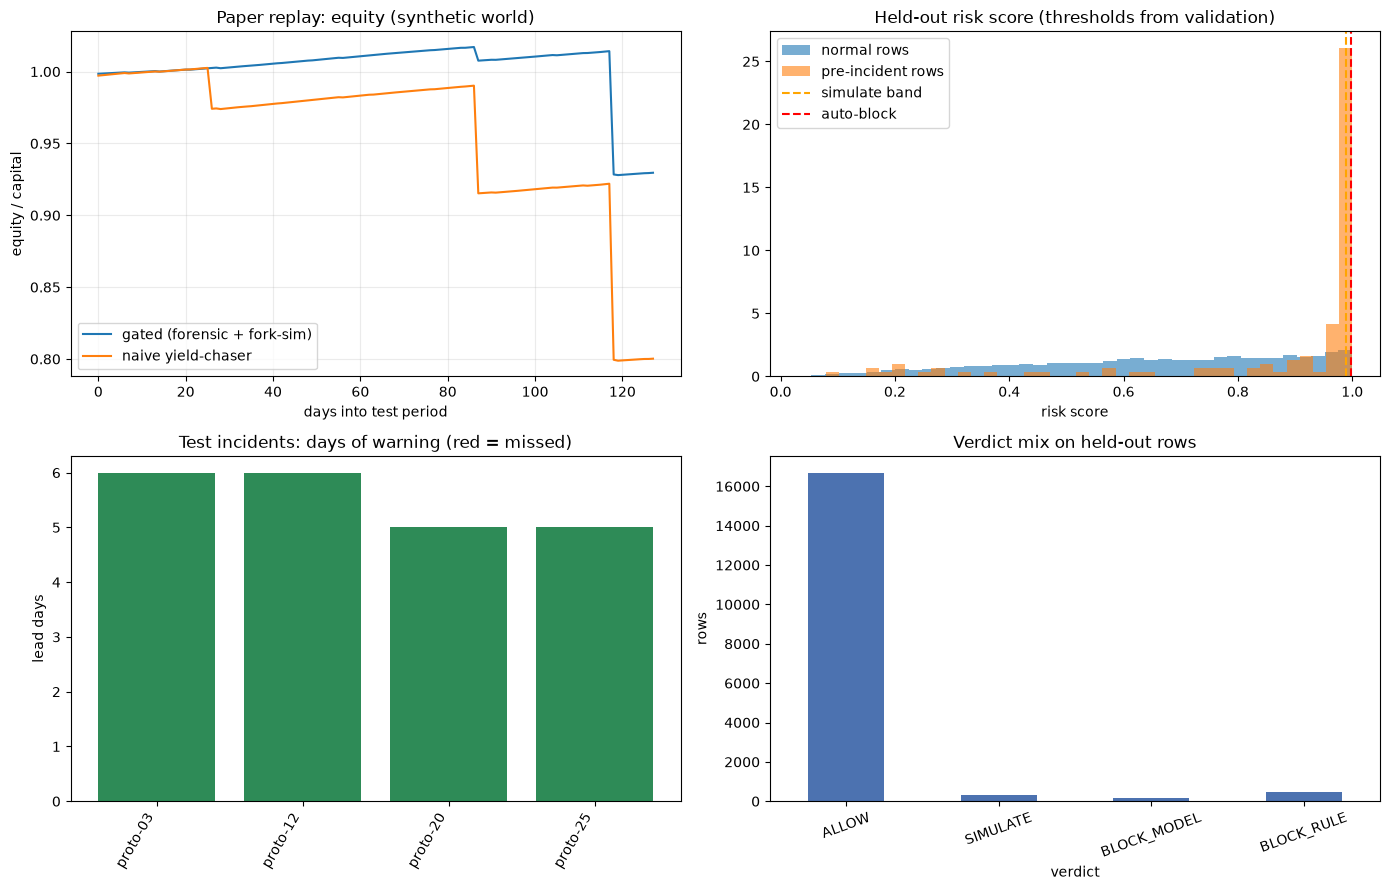

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for n, (eq, _, _) in runs.items():
    ax[0, 0].plot(eq.day_num - eq.day_num.min(), eq.equity / CFG.CAPITAL_USD, label=n)
ax[0, 0].set(title="Paper replay: equity (synthetic world)", xlabel="days into test period", ylabel="equity / capital"); ax[0, 0].legend(); ax[0, 0].grid(alpha=.25)

te = scored[(scored.split == "test") & (~scored.quarantine)]
ax[0, 1].hist(te.loc[te.label == 0, "risk_score"], bins=40, alpha=.6, density=True, label="normal rows")
if te.label.sum() > 0: ax[0, 1].hist(te.loc[te.label == 1, "risk_score"], bins=40, alpha=.6, density=True, label="pre-incident rows")
ax[0, 1].axvline(engine.t_sim, color="orange", ls="--", label="simulate band"); ax[0, 1].axvline(engine.t_block, color="red", ls="--", label="auto-block")
ax[0, 1].set(title="Held-out risk score (thresholds from validation)", xlabel="risk score"); ax[0, 1].legend()

if len(incident_table):
    it = incident_table.assign(lead=incident_table.lead_days.fillna(0))
    ax[1, 0].bar(range(len(it)), it.lead, color=np.where(it.detected, "#2e8b57", "#b44b4b"))
    ax[1, 0].set_xticks(range(len(it))); ax[1, 0].set_xticklabels(it.incident_id.str.split("|").str[0], rotation=60, ha="right")
ax[1, 0].set(title="Test incidents: days of warning (red = missed)", ylabel="lead days")

te.verdict.value_counts().reindex(["ALLOW", "SIMULATE", "BLOCK_MODEL", "BLOCK_RULE"]).fillna(0).plot.bar(ax=ax[1, 1], color="#4c72b0")
ax[1, 1].set(title="Verdict mix on held-out rows", ylabel="rows"); ax[1, 1].tick_params(axis="x", rotation=20)
fig.tight_layout(); plt.show()

## 9 · Switching to real data (when you decide it is worth the tokens/requests)
1. Set `CFG.USE_REAL_DATA = True` **and** `CFG.ALLOW_NETWORK = True` in the config cell. Start with `CFG.MAX_POOLS = 60`; the loader caches per pool under `artifacts/raw/charts/`, so reruns are free and a crash is resumable.
2. Leave `ALIASES = {}` and inspect `review_queue` (fuzzy candidates). Add an alias **only** after reading the source event.
3. Expect far fewer independent incidents than synthetic: if fewer than `MIN_POS_INCIDENTS` fall in the train window the engine automatically stays **anomaly-only** and says so in `engine.status`.
4. The incident-level table vs `chance_detection` is the number to believe; PR-AUC on correlated rows is not.
5. `EXPLOIT_LOSS_FRACTION`, `STRESS` and DEX depth remain **assumptions**: calibrate them from hack `amount` / protocol TVL and real pool depth before drawing conclusions.

**Deliberately out of scope here:** Solidity, wallets, RPC, keeper networks, Tenderly. `SimVault`/`Keeper`/`fork_dry_run` define the interface and invariants a real implementation must satisfy (the tests in §7 become your spec).